# This notebook is for help

In [35]:
import gymnasium as gym
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from scipy.ndimage import uniform_filter

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path

In [36]:
landuse_path = Path("../../data/land_use")

In [37]:
landuse_2010 = rasterio.open(landuse_path.joinpath("land_use_2010.tif")).read(1)
landuse_2015 = rasterio.open(landuse_path.joinpath("land_use_2015.tif")).read(1)
landuse_2017 = rasterio.open(landuse_path.joinpath("land_use_2017.tif")).read(1)

(478, 552)


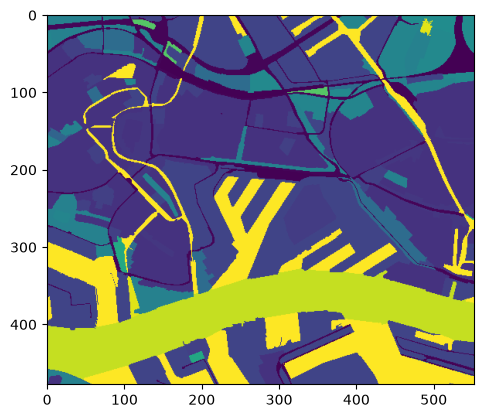

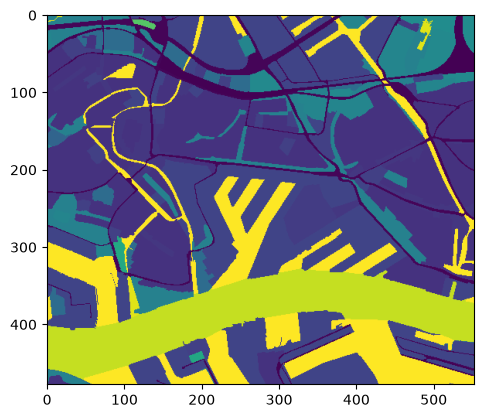

In [38]:
print(landuse_2010.shape)

plt.imshow(landuse_2010)
plt.show()

plt.imshow(landuse_2015)
plt.show()

# Check if all land-uses contain the same values

In [39]:
values_2010 = set(np.unique(landuse_2010))
values_2015 = set(np.unique(landuse_2015))
values_2017 = set(np.unique(landuse_2017))

# print("2010:", values_2010)
# print("2015:", values_2015)
# print("2017:", values_2017)

if values_2010 == values_2015 == values_2017:
    print("All years contain the same land-use values.")
else:
    print("Land-use values differ across years.")

All years contain the same land-use values.


# Mapping Values To Categories

In [40]:
RAILWAY_LABEL = 10
ROAD_LABEL = 11
RESIDENTIAL_LABEL = 20
HOSPITAL_LABEL = 21
PUBLIC_FACILITY_LABEL = 22
SOCIAL_FACILITY_LABEL = 23
INDUSTRY_LABEL = 24
CEMETERY_LABEL = 32
CONSTRUCTION_LABEL = 34
OTHER_SEMI_PAVED_LABEL = 35
PARK_LABEL = 40
SPORTS_LABEL = 41
GARDEN_LABEL = 42
DAY_RECREATION_LABEL = 43
NIGHT_RECREATION_LABEL = 44
AGRICULTURE_LABEL = 51
FOREST_LABEL = 60
WET_NATURE_LABEL = 62
WATER_LABELS = {
    72, 75, 78
}

In [41]:
STABLE_LABELS = [RAILWAY_LABEL, ROAD_LABEL, *WATER_LABELS]

In [42]:
classes = np.unique(landuse_2010)
n = len(classes)

# count changes from 2010 to 2015
counts = np.zeros((n, n), dtype=int)
for i, old in enumerate(classes):
    for j, new in enumerate(classes):
        counts[i, j] = np.sum((landuse_2010 == old) & (landuse_2015 == new))

# allow a change if it happened at least 20 times
allowed = counts >= 20

# allow transitions to itself
np.fill_diagonal(allowed, True)

# make stable labels stable
for label in STABLE_LABELS:
    i = list(classes).index(label)
    allowed[:, i] = True
    allowed[i, :] = False

print(pd.DataFrame(allowed, index=classes, columns=classes))


       10.0   11.0   20.0   21.0   22.0   23.0   24.0   32.0   34.0   35.0  \
10.0  False   True  False  False  False  False  False  False  False  False   
11.0  False  False  False  False  False  False  False  False  False  False   
20.0   True   True   True   True  False  False   True  False  False  False   
21.0   True   True   True   True  False  False  False  False  False  False   
22.0   True   True  False  False   True  False  False  False  False   True   
23.0   True   True   True   True  False   True   True  False   True  False   
24.0   True   True   True   True  False   True   True  False   True   True   
32.0   True   True  False  False  False  False  False   True  False  False   
34.0   True   True   True  False   True   True   True  False   True  False   
35.0   True   True  False  False  False  False  False  False  False   True   
40.0   True   True   True  False  False   True  False   True  False  False   
41.0   True   True   True   True  False   True  False  False  Fa

In [43]:
start  = np.searchsorted(classes, landuse_2010)
target = np.searchsorted(classes, landuse_2015)
print(start)
print(target)

[[10 10 10 ... 13 13 13]
 [10 10 10 ... 13 13 13]
 [10 10 10 ... 13 13 13]
 ...
 [11 11  2 ... 18 18 18]
 [11 11  2 ... 18 18 18]
 [11 11  2 ... 18 18 18]]
[[10 10 10 ... 13 13 13]
 [10 10 10 ... 13 13 13]
 [10 10 10 ... 13 13 13]
 ...
 [11 11  2 ... 18 18 18]
 [11 11  2 ... 18 18 18]
 [11 11  2 ... 18 18 18]]


In [44]:
class LandUseEnv(gym.Env):
    def __init__(self, start, target):
        super().__init__()
        self.start, self.target = start, target
        h, w = landuse_2010.shape
        self.action_space = gym.spaces.Box(0, n-1, shape=(h,w), dtype=np.int64)
        self.observation_space = gym.spaces.Box(0, n-1, shape=(h, w), dtype=np.int64)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed, options=options)
        return self.start, {}

    def step(self, actions):
        pass

env = LandUseEnv(start, target)


In [45]:
def make_features(state):
    # one hot encode the class of the state
    state_class = np.eye(n)[state]
    # distributions of classes around the cell
    around_classes = np.stack([uniform_filter(state_class[:, k], size=5) for k in range(n)], axis=-1)
    # TODO: Add distance to road as a feature
    # TODO: Add distance to hospital as a feature
    # TODO: Add distance to recreation area as a feature
    # TODO: Come up with more features
    # merge
    return np.concatenate([state_class, around_classes], axis=-1) # output stape is 2 * n


In [ ]:
model = Sequential([
    Input(2 * n),
    Dense(32, activation="tanh"),
    Dense(2 * n)
])
model.compile(
    optimizer="adam",
    loss="mse"
)

In [ ]:
def choose_actions(q_table, mask, epsilon):
    # select the best action for every cell from the q_table
    best_action = np.argmax(np.where(mask, q_table, -1e-9), axis=-1)
    # select random valid action
    rand = np.random.rand(*mask.shape)
    rand[~mask] = -1
    random_action = np.argmax(rand, axis=-1)
    explore = np.random.rand(len(best_action)) < epsilon
    return np.where(explore, random_action, best_action)


In [ ]:
# TODO: Training
# Every episode sample cells that will change, and cells that won't change to ensure balanced learning
